# Chapter 1 — Artificial Neural Networks

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mengrenman/artificial_intelligence_engines/blob/main/notebooks/01_introduction.ipynb)

*Companion notebook for J V Stone, **Artificial Intelligence Engines** (2020), Chapter 1.*

An artificial neural network is a set of interconnected model neurons, or **units** (Section 1.2).
Each unit does two things:

1. computes its **total input** as a weighted sum of the states of the units that feed it,
   $u = \sum_i w_i x_i = \mathbf{w}\cdot\mathbf{x}$;
2. passes $u$ through an **activation function** $f$ to obtain its output (state) $y = f(u)$.

Learning means adjusting the weights $w_i$ so that inputs produce the desired outputs — which raises the
*credit (or blame) assignment problem*: when the output is wrong, which weights are to blame?
The rest of the book is, in large part, a sequence of increasingly powerful answers to that question.

In [1]:
# Colab setup: install the companion package (does nothing when run locally).
try:
    import google.colab  # noqa: F401
    %pip install -q git+https://github.com/mengrenman/artificial_intelligence_engines
except ImportError:
    pass

In [2]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from aie.activations import (sigmoid, sigmoid_deriv, tanh, tanh_deriv,
                             relu, relu_deriv_from_input, step)

## Activation functions

The activation functions used in this book:

| name | $f(u)$ | $df/du$ | where in the book |
|---|---|---|---|
| step (threshold) | $+1$ if $u>0$ else $-1$ | $0$ (undefined at 0) | perceptrons (Fig 3.3), Hopfield nets (Ch 5) |
| sigmoid | $1/(1+e^{-u})$ | $y(1-y)$ | backprop hidden units (Eq 4.1–4.2) |
| tanh | $\tanh u$ | $1-y^2$ | common alternative to the sigmoid |
| ReLU | $\max(0,u)$ | $1$ if $u>0$ else $0$ | deep networks (Section 9.5) |

Note that `aie.activations` expresses the sigmoid and tanh derivatives in terms of the *output* $y$,
which is exactly what backprop needs (it already has $y$ from the forward pass).
The step function's derivative is zero almost everywhere — this is why it cannot be trained by
gradient descent, and why Chapter 4 replaces it with the smooth sigmoid.

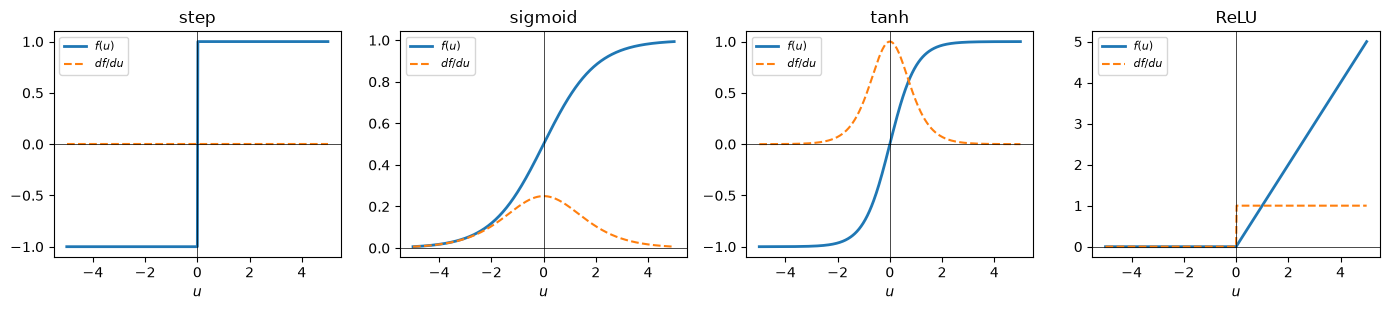

In [3]:
u = np.linspace(-5, 5, 501)
acts = {
    "step":    (step(u),    np.zeros_like(u)),
    "sigmoid": (sigmoid(u), sigmoid_deriv(sigmoid(u))),
    "tanh":    (tanh(u),    tanh_deriv(tanh(u))),
    "ReLU":    (relu(u),    relu_deriv_from_input(u)),
}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharex=True)
for ax, (name, (y, dy)) in zip(axes, acts.items()):
    ax.plot(u, y, label="$f(u)$", lw=2)
    ax.plot(u, dy, "--", label="$df/du$")
    ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
    ax.set_title(name); ax.set_xlabel("$u$"); ax.legend(fontsize=8)
fig.tight_layout()

The sigmoid's derivative peaks at $0.25$ (at $u=0$) and vanishes for large $|u|$; this is the root of
the *vanishing gradient* problem discussed in Section 4.5. ReLU keeps a derivative of 1 for all positive
inputs, which is one reason it dominates deep networks (Chapter 9).

## A forward pass by hand

Consider the 2-2-1 network of Figure 1.6: two input units, two sigmoidal hidden units, one output unit.
With hidden weight matrix $W^{(1)}$ (row $j$ holds the weights into hidden unit $j$) and output weights
$\mathbf{w}^{(2)}$, the forward pass is

$$ z_j = \sigma\Big(\sum_i W^{(1)}_{ji} x_i\Big), \qquad y = \sum_j w^{(2)}_j z_j .$$

We compute it once step by step and once with matrix operations.

In [4]:
x  = np.array([1.0, 0.5])
W1 = np.array([[ 0.8, -0.4],
               [-0.3,  0.9]])
w2 = np.array([1.5, -1.0])

# step by step
u1 = W1[0, 0] * x[0] + W1[0, 1] * x[1]
u2 = W1[1, 0] * x[0] + W1[1, 1] * x[1]
z1, z2 = sigmoid(u1), sigmoid(u2)
y = w2[0] * z1 + w2[1] * z2
print(f"hidden inputs  u = ({u1:.3f}, {u2:.3f})")
print(f"hidden states  z = ({z1:.4f}, {z2:.4f})")
print(f"output         y = {y:.4f}")

# the same thing in two lines of linear algebra
z = sigmoid(W1 @ x)
print("matrix form    y =", round(float(w2 @ z), 4))

hidden inputs  u = (0.600, 0.150)
hidden states  z = (0.6457, 0.5374)
output         y = 0.4311
matrix form    y = 0.4311


## A picture of the network

Below, the 2-2-1 network drawn with line widths proportional to $|w|$ (blue = positive, red = negative).
The input layer on the left is connected to the output through a **hidden** layer; it is the hidden units that
let a network represent mappings, such as exclusive OR, that are impossible for networks with only
input and output units (Chapters 2–4).

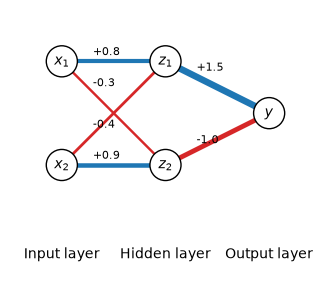

In [5]:
def draw_network(layers, weights, ax, labels):
    xs = np.arange(len(layers))
    pos = [[(xi, (n - 1) / 2 - k) for k in range(n)] for xi, n in zip(xs, layers)]
    for l, W in enumerate(weights):
        for j, (xj, yj) in enumerate(pos[l + 1]):
            for i, (xi, yi) in enumerate(pos[l]):
                w = W[j, i]
                ax.plot([xi, xj], [yi, yj], color="C0" if w > 0 else "C3",
                        lw=1 + 2.5 * abs(w), zorder=1)
                ax.text(xi + 0.3 * (xj - xi), yi + 0.3 * (yj - yi) + 0.06, f"{w:+.1f}", fontsize=8)
    for l, layer in enumerate(pos):
        for k, (xi, yi) in enumerate(layer):
            ax.add_patch(plt.Circle((xi, yi), 0.15, color="w", ec="k", zorder=2))
            ax.text(xi, yi, labels[l][k], ha="center", va="center", zorder=3)
    for xi, name in zip(xs, ["Input layer", "Hidden layer", "Output layer"]):
        ax.text(xi, -1.4, name, ha="center")
    ax.set_xlim(-0.5, len(layers) - 0.5); ax.set_ylim(-1.6, 1.0)
    ax.set_aspect("equal"); ax.axis("off")

fig, ax = plt.subplots(figsize=(6, 3.5))
draw_network([2, 2, 1], [W1, w2[None, :]], ax,
             [["$x_1$", "$x_2$"], ["$z_1$", "$z_2$"], ["$y$"]])

## Summary

* A unit = weighted sum $u=\mathbf{w}\cdot\mathbf{x}$ followed by an activation $y=f(u)$.
* The choice of $f$ matters: the step function gives crisp decisions but no useful gradient; smooth
  functions (sigmoid, tanh, ReLU) make gradient-based learning possible.
* Networks are built by wiring units into layers. The following notebooks train such networks:
  linear associative networks (Ch 2), perceptrons (Ch 3) and backprop networks (Ch 4).